# 1 · The air an engine breathes

The International Standard Atmosphere, stagnation properties, the mass-flow parameter and
corrected flow. Lesson: [01](../docs/lessons/01-atmosphere-and-compressible-flow.md) ·
Theory: [atmosphere and gas](../docs/atmosphere_and_gas.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from propulsion import plotting as P
from propulsion.flight import FlightCondition
from propulsion.units import FT, tsfc_to_lb_per_lbf_h

P.use_style()
np.set_printoptions(precision=4, suppress=True)
FL350 = FlightCondition.at_altitude(35000 * FT, 0.78, geopotential=True)
SLS = FlightCondition.sea_level_static()
from propulsion.atmosphere import isa, pressure_altitude
from propulsion.gas import AIR, COMBUSTION_GAS, mass_flow_parameter, stagnation_pressure_ratio

## The standard atmosphere at a few altitudes

In [2]:
for z in [0.0, 5000.0, 11000.0, 15000.0, 20000.0]:
    a = isa(z)
    print(f"z = {z/1e3:5.1f} km   T = {float(a.T):7.2f} K   P = {float(a.P):9.1f} Pa   "
          f"rho = {float(a.rho):.4f} kg/m3   a = {float(a.a):6.1f} m/s")

z =   0.0 km   T =  288.15 K   P =  101325.0 Pa   rho = 1.2250 kg/m3   a =  340.3 m/s
z =   5.0 km   T =  255.68 K   P =   54048.3 Pa   rho = 0.7364 kg/m3   a =  320.5 m/s
z =  11.0 km   T =  216.77 K   P =   22700.0 Pa   rho = 0.3648 kg/m3   a =  295.2 m/s
z =  15.0 km   T =  216.65 K   P =   12111.8 Pa   rho = 0.1948 kg/m3   a =  295.1 m/s
z =  20.0 km   T =  216.65 K   P =    5529.3 Pa   rho = 0.0889 kg/m3   a =  295.1 m/s


## Cruise at FL350, Mach 0.78

Flight levels are pressure altitudes, so the ISA is evaluated at 35,000 ft *geopotential*.

In [3]:
print(f"T0 = {FL350.T0:.2f} K, P0 = {FL350.P0:.0f} Pa, V0 = {float(FL350.V0()):.1f} m/s")
print(f"ram: tau_r = {float(FL350.tau_r()):.4f}, pi_r = {float(FL350.pi_r()):.4f}")
print(f"fan face: Tt0 = {float(FL350.Tt0()):.1f} K, Pt0 = {float(FL350.Pt0()):.0f} Pa")
print(f"pressure altitude of 30 kPa: {pressure_altitude(30e3, geopotential=True)/FT:.0f} ft")

T0 = 218.81 K, P0 = 23842 Pa, V0 = 231.2 m/s
ram: tau_r = 1.1217, pi_r = 1.4947
fan face: Tt0 = 245.4 K, Pt0 = 35636 Pa
pressure altitude of 30 kPa: 30065 ft


## Mass-flow parameter and corrected flow

A 1.6 m² fan face at Mach 0.6 passes very different *physical* flows at sea level and at
cruise, but the same *corrected* flow.

sea-level static  mdot =  325.0 kg/s   corrected =  325.0 kg/s
FL350, M 0.78     mdot =  123.8 kg/s   corrected =  325.0 kg/s


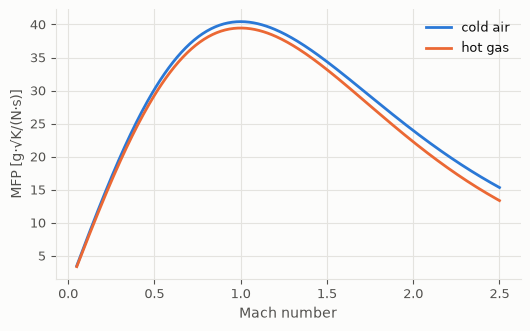

In [4]:
mfp = float(mass_flow_parameter(0.6, AIR))
for name, fc in [("sea-level static", SLS), ("FL350, M 0.78", FL350)]:
    Tt, Pt = float(fc.Tt0()), float(fc.Pt0())
    mdot = mfp * Pt * 1.6 / np.sqrt(Tt)
    corrected = mdot * np.sqrt(Tt / 288.15) / (Pt / 101325.0)
    print(f"{name:17s} mdot = {mdot:6.1f} kg/s   corrected = {corrected:6.1f} kg/s")
M = np.linspace(0.05, 2.5, 300)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(M, mass_flow_parameter(M, AIR) * 1e3, label="cold air")
ax.plot(M, mass_flow_parameter(M, COMBUSTION_GAS) * 1e3, label="hot gas")
ax.set_xlabel("Mach number"); ax.set_ylabel("MFP [g·√K/(N·s)]"); ax.legend()
plt.show()